# Evidencia de aprendizaje 3 – Optimización de procesos de desarrollo

**Estudiante:** Alejandro Arango Calderón · **Curso:** Programación para Análisis de Datos (PREICA2602B020048)
**Docente:** Andrés Felipe Palacio · IU Digital de Antioquia · Noviembre de 2026

**Repositorio:** https://github.com/Biershoot/monitor-precios-falabella
**Aplicación desplegada en Render:** https://monitor-precios-falabella.onrender.com

En este notebook muestro paso a paso lo que hice en la Evidencia 3 sobre el proyecto que vengo
construyendo desde la Evidencia 1 (scraping de los audífonos Xiaomi Redmi Buds 6 Play en Falabella):

1. Revisar por qué falló el scraping programado del 16 de noviembre y probar la corrección.
2. Probar la aplicación web Flask (tablero, catálogo y API REST) sin levantar un servidor.
3. Ejecutar las pruebas automatizadas igual que lo hace la CI.
4. Revisar los archivos de despliegue (Dockerfile, render.yaml y workflows de GitHub Actions).
5. Consultar la aplicación ya desplegada en Render y comprobar que tiene la última versión.
6. Revisar las ejecuciones de GitHub Actions.
7. Analizar los datos que quedaron en el historial.

El código fuente completo está en el repositorio; aquí importo el paquete `monitor_precios` directamente.

In [1]:
import json
import subprocess
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
import requests

# El notebook está en notebooks/, el paquete está en la carpeta de arriba
RAIZ = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(RAIZ))

import monitor_precios
from monitor_precios import analisis, extraccion, limpieza
from monitor_precios.web import create_app

import logging
logging.getLogger("matplotlib").setLevel(logging.WARNING)
%matplotlib inline

APP_URL = "https://monitor-precios-falabella.onrender.com"
pd.set_option("display.max_colwidth", 60)
print("Versión del paquete:", monitor_precios.__version__)
print("Carpeta del proyecto:", RAIZ.name)

Versión del paquete: 2.0.0
Carpeta del proyecto: monitor-precios-falabella


## 1. El problema: el scraping programado falló el 16 de noviembre

El workflow semanal de la EA2 terminó en rojo con el mensaje *«Solo se obtuvieron 54 productos (mínimo 100)»*.
Lo bueno es que la validación que puse en la EA2 funcionó: como hubo pocos productos, no guardó nada y el
historial no se dañó. Así quedó el historial antes de la corrección (la última fila buena es del 9 de noviembre):

In [2]:
historial = pd.read_csv(RAIZ / "datos" / "historial.csv")
historial

,fecha,productos,precio_mediano,descuento_promedio,precio_articulo,pct_mas_baratos,fuente
0,2026-10-22,256,85499.5,29.8,59900,26.6,NaN
1,2026-11-04,249,74990.0,27.3,59900,33.3,NaN
2,2026-11-08,251,69900.0,26.6,59900,32.7,busqueda
3,2026-11-09,255,69900.0,27.2,59900,31.0,busqueda
4,2026-11-18,244,106400.0,27.7,59900,17.2,busqueda


Al revisar a mano encontré que Falabella ahora **ignora el parámetro `page`** en algunas búsquedas:
las páginas 1 a 5 de «audífonos inalámbricos» traían exactamente los mismos productos. El scraper de la EA2
descargaba 5 páginas iguales y, al quitar repetidos, quedaban unos 54 productos.

La corrección tiene dos partes:

- `scrapear_catalogo()` ahora para cuando una página no trae ningún producto nuevo.
- `scrapear_varias_busquedas()` arma el catálogo con 5 términos relacionados (una página por término).

Lo pruebo sin internet, simulando una página que siempre devuelve lo mismo, igual que en las pruebas de pytest:

In [3]:
from tests.conftest import pagina_html, producto

pagina_repetida = pagina_html({"props": {"pageProps": {"results": [
    producto("1", "Audífonos A", "JBL", 99900, 149900),
    producto("2", "Audífonos B", "SONY", 179900, 249900),
]}}})

urls_pedidas = []
def descargar_falso(url):
    urls_pedidas.append(url)
    return pagina_repetida          # Falabella devolviendo siempre la página 1

productos = extraccion.scrapear_catalogo("audifonos tws", paginas=5, pausa=0, descargar_fn=descargar_falso)
print(f"Productos: {len(productos)}  |  páginas pedidas: {len(urls_pedidas)} de 5")
for url in urls_pedidas:
    print("  ", url)

Productos: 2  |  páginas pedidas: 2 de 5
   https://www.falabella.com.co/falabella-co/search?Ntt=audifonos+tws&page=1
   https://www.falabella.com.co/falabella-co/search?Ntt=audifonos+tws&page=2


Con la página repetida, el scraper pide la página 2, ve que no hay nada nuevo y para. Antes habría hecho
las 5 peticiones para nada. Estos son los términos que uso ahora (sin marcas, para no inflar a Xiaomi):

In [4]:
list(extraccion.TERMINOS)

['audifonos inalambricos',
 'audifonos earbuds',
 'audifonos tws',
 'audifonos deportivos',
 'audifonos diadema bluetooth']

## 2. La aplicación web

La aplicación está en `monitor_precios/web/`. Uso el patrón *application factory* (`create_app`), así que en
las pruebas (y aquí) puedo crear la aplicación con otra configuración y usar el cliente de pruebas de Flask,
que hace peticiones sin levantar un servidor.

In [5]:
app = create_app({"TESTING": True, "DATOS_DIR": str(RAIZ / "datos"), "COMMIT": "notebook"})
cliente = app.test_client()

print("Rutas registradas:")
for regla in sorted(app.url_map.iter_rules(), key=lambda r: r.rule):
    if regla.endpoint != "static":
        print(f"  {sorted(regla.methods - {'HEAD', 'OPTIONS'})}  {regla.rule}")

2026-11-18 02:50:35,554 INFO Monitor de precios v2.0.0 (development) - datos en C:\Users\alejo\Documents\F35 - Evidencia de aprendizaje 3. Optimización procesos de desarrollo\monitor-precios-falabella\datos


Rutas registradas:
  ['GET']  /
  ['GET']  /api/articulo
  ['GET']  /api/catalogo
  ['GET']  /api/historial
  ['GET']  /api/indicadores
  ['GET']  /api/marcas
  ['GET']  /api/salud
  ['GET']  /catalogo


In [6]:
respuesta = cliente.get("/api/salud")
print("HTTP", respuesta.status_code)
print(json.dumps(respuesta.get_json(), indent=2, ensure_ascii=False))

HTTP 200
{
  "estado": "ok",
  "version": "2.0.0",
  "commit": "notebook",
  "entorno": "development",
  "hora_servidor": "2026-11-18T07:50:35+00:00",
  "datos": "ok",
  "ultima_extraccion": "2026-11-18",
  "productos": 244
}


In [7]:
# Catálogo filtrado: audífonos Xiaomi ordenados del más barato al más caro
cuerpo = cliente.get("/api/catalogo?marca=XIAOMI&orden=precio_asc&limite=10").get_json()
print("Total con el filtro:", cuerpo["total"])
pd.DataFrame(cuerpo["productos"])[["nombre", "precio_oferta", "precio_normal", "descuento_pct", "num_resenas"]]

Total con el filtro: 10


,nombre,precio_oferta,precio_normal,descuento_pct,num_resenas
0,Auriculares Redmi Buds 6 Play Negro,54990,99900,45.0,539
1,Auriculares Redmi Buds 6 Play Rosa,54990,99900,45.0,3
2,Auriculares Redmi Buds 6 Play Blanco,54990,99900,45.0,549
3,Audífonos earbuds Bluetooth Redmi Buds 6 Play,59900,99900,40.0,1985
4,Audífonos bluetooth Redmi Buds 8 Active Ng,99900,139900,28.6,8
5,Audífonos bluetooth Redmi Buds 8 Lite Noise Cancelling,119900,149900,20.0,26
6,Audífonos de diadema Redmi Headphones Neo Obsidian,249900,449900,44.5,0
7,Audífonos Diadema Bluetooth Redmi Headphones Neo Cancela...,249900,359900,30.6,0
8,Audífonos Diadema Bluetooth Redmi Headphones Neo Cancela...,249900,359900,30.6,0
9,Audífonos Redmi Buds 8 Pro,279900,699900,60.0,4


In [8]:
# Los errores también responden en JSON con el código HTTP adecuado
for ruta in ["/api/catalogo?precio_max=barato", "/api/catalogo?orden=nombre", "/api/no-existe"]:
    r = cliente.get(ruta)
    print(r.status_code, ruta, "->", r.get_json())

400 /api/catalogo?precio_max=barato -> {'error': "El parámetro 'precio_max' debe ser un número"}
400 /api/catalogo?orden=nombre -> {'error': 'Orden no válido: nombre. Use uno de precio_asc, precio_desc, descuento, resenas'}
404 /api/no-existe -> {'error': 'No existe la ruta /api/no-existe'}


In [9]:
# La página del tablero (HTML) también se puede probar
html = cliente.get("/").get_data(as_text=True)
print("¿Muestra el artículo?", "Redmi Buds 6 Play" in html)
print("¿Tiene las gráficas de Chart.js?", "graficaHistorial" in html and "graficaPrecios" in html)

¿Muestra el artículo? True
¿Tiene las gráficas de Chart.js? True


## 3. Pruebas automatizadas

Ejecuto lo mismo que corre el job `pruebas` de `ci.yml`: el análisis de estilo con **ruff** y **pytest** con
cobertura. En la CI esto se repite en Python 3.11, 3.12 y 3.13, y el job falla si la cobertura baja de 90 %.

In [10]:
resultado = subprocess.run([sys.executable, "-m", "pytest", "--cov", "-q", "-p", "no:cacheprovider"],
                           cwd=RAIZ, capture_output=True, text=True)
print("\n".join(resultado.stdout.strip().splitlines()[-16:]))

_______________ coverage: platform win32, python 3.15.2-final-0 _______________

Name                              Stmts   Miss  Cover
-----------------------------------------------------
monitor_precios\__init__.py           1      0   100%
monitor_precios\__main__.py          90      1    99%
monitor_precios\analisis.py          29      0   100%
monitor_precios\extraccion.py        93      1    99%
monitor_precios\limpieza.py          25      0   100%
monitor_precios\reporte.py           71      0   100%
monitor_precios\web\__init__.py     102      0   100%
monitor_precios\web\config.py         6      0   100%
monitor_precios\web\datos.py         56      0   100%
-----------------------------------------------------
TOTAL                               473      2    99%
============================= 68 passed in 2.72s ==============================


## 4. Archivos de despliegue

### 4.1 Dockerfile
La misma imagen se usa en tres lugares: en la CI (para probar que el contenedor arranca), en `ghcr.io`
(registro de imágenes) y en Render (producción).

In [11]:
print((RAIZ / "Dockerfile").read_text(encoding="utf-8"))

# Imagen de la aplicación web del monitor de precios.
# La usa Render para desplegar (runtime: docker) y la CI para probar que el contenedor arranca.
FROM python:3.12-slim

ENV PYTHONDONTWRITEBYTECODE=1 \
    PYTHONUNBUFFERED=1 \
    PIP_NO_CACHE_DIR=1 \
    PIP_DISABLE_PIP_VERSION_CHECK=1 \
    MPLCONFIGDIR=/tmp/matplotlib

WORKDIR /app

# Primero solo las dependencias, para que Docker reutilice esta capa
# mientras requirements.txt no cambie.
COPY requirements.txt .
RUN pip install -r requirements.txt

COPY monitor_precios/ monitor_precios/
COPY datos/ datos/

# No correr la aplicación como root
RUN useradd --create-home --uid 1000 app
USER app

# APP_COMMIT se pasa en la CI; en Render se usa RENDER_GIT_COMMIT
ARG APP_COMMIT=local
ENV APP_COMMIT=${APP_COMMIT} \
    APP_ENV=production \
    DATOS_DIR=/app/datos \
    PORT=10000

EXPOSE 10000

HEALTHCHECK --interval=30s --timeout=5s --start-period=20s --retries=3 \
  CMD python -c "import os, urllib.request; urllib.request.urlopen('htt

### 4.2 render.yaml (Blueprint de Render)
Con este archivo Render crea el servicio sin configurar nada a mano en el panel (infraestructura como código).
`autoDeployTrigger: "off"` hace que Render no despliegue solo: el despliegue lo dispara GitHub Actions cuando pasan las pruebas.

In [12]:
print((RAIZ / "render.yaml").read_text(encoding="utf-8"))

# Blueprint de Render (infraestructura como código).
# En Render: New > Blueprint > seleccionar este repositorio. Render crea el servicio con esta configuración.
services:
  - type: web
    name: monitor-precios-falabella
    runtime: docker            # construye la imagen con el Dockerfile del repositorio
    plan: free
    region: oregon
    branch: main
    dockerfilePath: ./Dockerfile
    healthCheckPath: /api/salud
    # No despliega solo con cada commit: el despliegue lo dispara GitHub Actions (cd.yml)
    # con el Deploy Hook, y solo después de que pasan las pruebas.
    autoDeployTrigger: "off"
    envVars:
      - key: APP_ENV
        value: production
      - key: DATOS_DIR
        value: /app/datos
      - key: LIMITE_MAXIMO
        value: "500"
      - key: POR_PAGINA
        value: "50"
      - key: WEB_CONCURRENCY
        value: "2"



### 4.3 Workflows de GitHub Actions
Resumen de los disparadores y los jobs de cada workflow:

In [13]:
import re

for archivo in sorted((RAIZ / ".github" / "workflows").glob("*.yml")):
    texto = archivo.read_text(encoding="utf-8")
    nombre = re.search(r"^name: (.+)$", texto, re.M).group(1)
    jobs = re.findall(r"^  ([a-z-]+):\n(?:    .*\n)*?    (?:name|uses): (.+)$", texto, re.M)
    print(f"{archivo.name}  ->  {nombre}")
    for job, detalle in jobs:
        print(f"    job {job:16s} {detalle}")

cd.yml  ->  CD - despliegue
    job pruebas          ./.github/workflows/ci.yml
    job construir-sitio  Construir el sitio estático
    job pages            Publicar en GitHub Pages
    job imagen           Publicar imagen en ghcr.io
    job render           Desplegar en Render
ci.yml  ->  CI - pruebas
    job pruebas          Lint y pruebas (Python ${{ matrix.python }})
    job contenedor       Construir y probar la imagen Docker
release.yml  ->  Release
    job pruebas          ./.github/workflows/ci.yml
    job publicar         Crear el release
scraping.yml  ->  Scraping programado
    job scrapear         Extraer datos y actualizar historial
    job desplegar        ./.github/workflows/cd.yml


## 5. La aplicación desplegada en Render

Ahora consulto la aplicación real. El plan gratis de Render apaga el servicio después de 15 minutos sin
visitas, así que la primera petición puede tardar (por eso uso un `timeout` de 90 segundos).

Lo más importante es comprobar que **el commit que responde Render es el último commit de `main`**: así sé que
el pipeline desplegó la versión correcta. Es la misma comprobación que hace el job *Desplegar en Render* de `cd.yml`.

In [14]:
salud = requests.get(f"{APP_URL}/api/salud", timeout=90).json()
print(json.dumps(salud, indent=2, ensure_ascii=False))

commit_main = subprocess.run(["git", "rev-parse", "origin/main"], cwd=RAIZ,
                             capture_output=True, text=True).stdout.strip()
print("\nÚltimo commit de main:", commit_main)
print("¿Render tiene la última versión?", salud["commit"] == commit_main)

{
  "estado": "ok",
  "version": "2.0.0",
  "commit": "6ce0dab9688da350abf49ec216d4e8e09b76b050",
  "entorno": "production",
  "hora_servidor": "2026-11-18T07:50:43+00:00",
  "datos": "ok",
  "ultima_extraccion": "2026-11-18",
  "productos": 244
}

Último commit de main: 6ce0dab9688da350abf49ec216d4e8e09b76b050
¿Render tiene la última versión? True


In [15]:
# Prueba de humo: cada ruta debe responder 200
for ruta in ["/", "/catalogo", "/catalogo?marca=XIAOMI", "/api/indicadores", "/api/historial", "/api/marcas"]:
    r = requests.get(APP_URL + ruta, timeout=90)
    print(f"{r.status_code}  {r.elapsed.total_seconds():5.2f} s  {ruta}")

200   0.27 s  /


200   0.55 s  /catalogo


200   0.26 s  /catalogo?marca=XIAOMI


200   0.24 s  /api/indicadores


200   0.25 s  /api/historial


200   0.28 s  /api/marcas


## 6. Ejecuciones de GitHub Actions

Con la API REST pública de GitHub traigo las últimas ejecuciones de los workflows del repositorio.

In [16]:
api = "https://api.github.com/repos/Biershoot/monitor-precios-falabella/actions/runs"
datos = requests.get(api, params={"per_page": 60}, timeout=30).json()["workflow_runs"]
runs = pd.DataFrame([{"createdAt": r["created_at"], "workflowName": r["name"], "event": r["event"],
                      "headBranch": r["head_branch"], "conclusion": r["conclusion"],
                      "displayTitle": r["display_title"]} for r in datos])
# dejo por fuera las ejecuciones internas de Dependabot y las CI de sus ramas
runs = runs[(runs["event"] != "dynamic") & ~runs["headBranch"].str.startswith("dependabot")]
runs["createdAt"] = pd.to_datetime(runs["createdAt"]).dt.strftime("%Y-%m-%d %H:%M")
runs[["createdAt", "workflowName", "event", "headBranch", "conclusion", "displayTitle"]].head(15)

,createdAt,workflowName,event,headBranch,conclusion,displayTitle
0,2026-11-18 07:41,CI - pruebas,push,develop,success,datos: actualización automática del 2026-11-18
1,2026-11-18 07:41,Release,push,v2.0.0,success,datos: actualización automática del 2026-11-18
2,2026-11-18 07:38,Scraping programado,workflow_dispatch,main,success,Scraping programado
31,2026-11-18 07:34,CD - despliegue,push,main,success,Merge pull request #12 from Biershoot/release/v2.0.0
32,2026-11-18 07:32,CI - pruebas,pull_request,release/v2.0.0,success,release: v2.0.0 – aplicación web desplegada en Render
33,2026-11-18 07:29,CI - pruebas,push,release/v2.0.0,success,chore: versión 2.0.0
34,2026-11-18 07:28,CI - pruebas,push,develop,success,Merge pull request #11 from Biershoot/docs/ea3
35,2026-11-18 07:27,CI - pruebas,pull_request,docs/ea3,success,"docs: README, guía de despliegue en Render y flujo DevOp..."
36,2026-11-18 07:27,CI - pruebas,push,docs/ea3,success,docs: guía de despliegue en Render y flujo DevOps actual...
37,2026-11-18 07:27,CI - pruebas,push,develop,success,Merge pull request #10 from Biershoot/feature/alertas-pr...


In [17]:
resumen = (runs.groupby(["workflowName", "conclusion"]).size().unstack(fill_value=0))
resumen

conclusion,failure,success
workflowName,,
CD - despliegue,0,1
CD - despliegue en GitHub Pages,0,1
CI - pruebas,0,25
Release,0,1
Scraping programado,1,3


## 7. Análisis de los datos del historial

Después de la corrección lancé el workflow de scraping a mano. El bot de GitHub Actions guardó la extracción del
18 de noviembre y el CD redesplegó Render con esos datos. Traigo el historial desde la API de la aplicación desplegada:

In [18]:
hist = pd.DataFrame(requests.get(f"{APP_URL}/api/historial", timeout=90).json())
hist

,fecha,productos,precio_mediano,descuento_promedio,precio_articulo,pct_mas_baratos,fuente
0,2026-10-22,256,85499.5,29.8,59900,26.6,busqueda
1,2026-11-04,249,74990.0,27.3,59900,33.3,busqueda
2,2026-11-08,251,69900.0,26.6,59900,32.7,busqueda
3,2026-11-09,255,69900.0,27.2,59900,31.0,busqueda
4,2026-11-18,244,106400.0,27.7,59900,17.2,busqueda


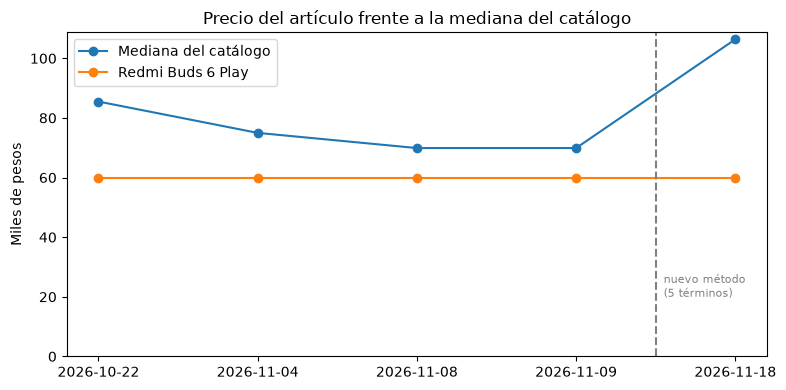

In [19]:
fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(hist["fecha"], hist["precio_mediano"] / 1000, marker="o", label="Mediana del catálogo")
ax.plot(hist["fecha"], hist["precio_articulo"] / 1000, marker="o", label="Redmi Buds 6 Play")
ax.axvline(3.5, color="gray", linestyle="--")
ax.text(3.55, 20, "nuevo método\n(5 términos)", color="gray", fontsize=8)
ax.set_ylabel("Miles de pesos")
ax.set_ylim(bottom=0)
ax.set_title("Precio del artículo frente a la mediana del catálogo")
ax.legend()
plt.tight_layout()
plt.show()

El precio del artículo no cambió ($59.900, 40 % de descuento), por eso el comando `alerta` no abrió ningún issue.
Lo que sí cambió mucho fue la mediana del catálogo: pasó de $69.900 a $106.400. Antes de concluir que los
audífonos subieron de precio, reviso cómo quedó compuesto el catálogo nuevo:

In [20]:
nuevo = pd.read_csv(RAIZ / "datos" / "catalogo_ultimo.csv")
anterior = pd.read_csv(RAIZ / "datos" / "catalogos" / "catalogo_2026-11-09.csv")

por_termino = (nuevo.groupby("busqueda")
               .agg(productos=("id_producto", "count"), precio_mediano=("precio_oferta", "median"))
               .sort_values("precio_mediano"))
print("Mediana del catálogo del 9 de noviembre:", anterior["precio_oferta"].median())
print("Productos que están en los dos catálogos:",
      len(set(nuevo["id_producto"].astype(str)) & set(anterior["id_producto"].astype(str))), "de", len(nuevo))
por_termino

Mediana del catálogo del 9 de noviembre: 69900.0
Productos que están en los dos catálogos: 36 de 244


,productos,precio_mediano
busqueda,,
audifonos tws,51,65000.0
audifonos diadema bluetooth,50,94400.0
audifonos deportivos,46,103000.0
audifonos earbuds,45,119990.0
audifonos inalambricos,52,248400.0


La primera página de «audífonos inalámbricos» ahora muestra sobre todo modelos premium (mediana de $248.400),
y solo 36 de los 244 productos coinciden con el catálogo del 9 de noviembre. Es decir, **el salto de la mediana
se debe a que cambió la muestra (el orden en que Falabella muestra los resultados y el método de extracción), no a
que los audífonos hayan subido de precio**. Por eso, en el historial, los valores desde el 18 de noviembre no se
deben comparar directamente con los anteriores. Lo dejo marcado en la gráfica con la línea punteada.

Aun así, la conclusión de las evidencias anteriores se mantiene: en todos los términos de búsqueda, la mayoría
de los productos cuesta más que el artículo.

In [21]:
articulo = json.loads((RAIZ / "datos" / "articulo_ultimo.json").read_text(encoding="utf-8"))
precio = articulo["precio_oferta"]
tabla = (nuevo.groupby("busqueda")["precio_oferta"]
         .apply(lambda s: round((s < precio).mean() * 100, 1))
         .rename("% de productos más baratos que el artículo")
         .to_frame())
tabla.loc["TOTAL"] = round((nuevo["precio_oferta"] < precio).mean() * 100, 1)
tabla

,% de productos más baratos que el artículo
busqueda,
audifonos deportivos,26.1
audifonos diadema bluetooth,14.0
audifonos earbuds,13.3
audifonos inalambricos,7.7
audifonos tws,25.5
TOTAL,17.2


Un detalle curioso: en el catálogo aparecen otras publicaciones del mismo Redmi Buds 6 Play, de otros vendedores
del marketplace, a un precio menor que la publicación de Falabella que vengo monitoreando:

In [22]:
nuevo[nuevo["nombre"].str.contains("Buds 6 Play", case=False)][["nombre", "vendedor", "precio_oferta", "descuento_pct"]]

,nombre,vendedor,precio_oferta,descuento_pct
11,Audífonos earbuds Bluetooth Redmi Buds 6 Play,Falabella,59900,40.0
15,Auriculares Redmi Buds 6 Play Negro,River Technology Sas,54990,45.0
36,Auriculares Redmi Buds 6 Play Rosa,River Technology Sas,54990,45.0
46,Auriculares Redmi Buds 6 Play Blanco,River Technology Sas,54990,45.0


## Conclusiones del notebook

- La validación de mínimo de productos de la EA2 evitó que se guardaran datos malos cuando Falabella cambió su paginación.
  La corrección se hizo con el mismo flujo de siempre: rama `fix/`, pruebas, PR con la CI en verde y merge.
- La aplicación web se puede probar completa con el cliente de pruebas de Flask, sin servidor y sin internet.
  Las 68 pruebas pasan con 99 % de cobertura.
- La aplicación desplegada en Render responde con el mismo commit que tiene `main`, lo que demuestra que el
  pipeline de CD desplegó la versión correcta de forma automática.
- El artículo sigue siendo una compra competitiva: a $59.900, solo el 17,2 % del catálogo cuesta menos. El salto de la
  mediana se explica por el cambio en la muestra y no por un aumento real de precios, y así lo dejo documentado.